# Projet final : les récoltes agricoles

**Équipe :** (ekip001.DALEUS Roodlyson, OLESTIL Roubens, MICHEL MARX Darwin)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [12]:
print(brut.shape)
brut.info()
print(brut.isna().sum())
print("doublons exacts :", brut.duplicated().sum())
for c in ["saison", "departement", "culture"]:
    print(brut[c].value_counts(dropna=False), "\n")
for c in ["surface_ha", "production_t"]:
    s = brut[c].dropna().astype(str)
    print(c, "non numériques :", s[~s.str.fullmatch(r"\d+")].head(8).tolist())

(408, 6)
<class 'pandas.DataFrame'>
RangeIndex: 408 entries, 0 to 407
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   annee         408 non-null    int64
 1   saison        408 non-null    str  
 2   departement   408 non-null    str  
 3   culture       408 non-null    str  
 4   surface_ha    408 non-null    str  
 5   production_t  393 non-null    str  
dtypes: int64(1), str(5)
memory usage: 30.8 KB
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64
doublons exacts : 18
saison
Printemps    204
Automne      204
Name: count, dtype: int64 

departement
Nord-Est       40
Ouest          39
Sud            37
Artibonite     35
Nord           35
Centre         33
Sud-Est        32
Nippes         31
Nord-Ouest     26
Grand'Anse     24
GRAND'ANSE      5
NORD-OUEST      4
NIPPES          4
nord-ouest      4
 Grand'Anse     4
Nippes          4
ouest 

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [13]:
import unicodedata

# --- Kopi ak fichye referans yo
propre = brut.copy()
cultures = pd.read_csv("donnees/cultures.csv")
departements = pd.read_csv("donnees/departements.csv")

# --- 1. Korije tèks yo (majiskil, aksan, espas)
def cle(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return s.strip().lower()

def recaler(serie, bonnes_valeurs):
    table = {cle(v): v for v in bonnes_valeurs}
    return serie.map(lambda x: table.get(cle(x)))

print("TEXTES avant :", propre.culture.nunique(), "cultures,", propre.departement.nunique(), "départements,", propre.saison.nunique(), "saisons")
propre["culture"] = recaler(propre["culture"], cultures.culture)
propre["departement"] = recaler(propre["departement"], departements.departement)
propre["saison"] = recaler(propre["saison"], ["Printemps", "Automne"])
print("TEXTES après :", propre.culture.nunique(), "cultures,", propre.departement.nunique(), "départements,", propre.saison.nunique(), "saisons")

# --- 2. Korije chif yo (retire t, ha, espas)
for c in ["surface_ha", "production_t"]:
    propre[c] = pd.to_numeric(
        propre[c].astype(str).str.replace(r"[^\d.]", "", regex=True),
        errors="coerce")
print("\nCHIFFRES :", propre[["surface_ha", "production_t"]].dtypes.to_dict())

# --- 3. Retire doublon
avant = len(propre)
propre = propre.drop_duplicates()
print("\nDOUBLONS avant :", avant, "| après :", len(propre), "| supprimées :", avant - len(propre))

# --- 4. Retire liy ki vid
avant = len(propre)
propre = propre.dropna().reset_index(drop=True)
print("VIDES avant :", avant, "| après :", len(propre), "| supprimées :", avant - len(propre))

# --- 5. Kontwòl final
print("\nFINAL :", propre.shape)
print("vides :", propre.isna().sum().sum(), "| doublons :", propre.duplicated().sum())
print(propre.saison.nunique(), "saisons,", propre.departement.nunique(), "départements,", propre.culture.nunique(), "cultures")
assert propre.shape == (376, 6)

TEXTES avant : 33 cultures, 44 départements, 2 saisons
TEXTES après : 7 cultures, 10 départements, 2 saisons

CHIFFRES : {'surface_ha': dtype('int64'), 'production_t': dtype('float64')}

DOUBLONS avant : 408 | après : 390 | supprimées : 18
VIDES avant : 390 | après : 376 | supprimées : 14

FINAL : (376, 6)
vides : 0 | doublons : 0
2 saisons, 10 départements, 7 cultures


## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [14]:
pluies = pd.read_csv("donnees/pluies.csv")
n = len(propre)
complet = propre.merge(cultures, on="culture", how="left")
print("après cultures :", n, "->", len(complet))
complet = complet.merge(pluies, on=["annee", "saison", "departement"], how="left")
print("après pluies :", len(complet))
complet = complet.merge(departements, on="departement", how="left")
print("après départements :", len(complet))
complet["rendement_t_ha"] = complet.production_t / complet.surface_ha
complet["valeur_htg"] = complet.production_t * 1000 * complet.prix_htg_kg
assert len(complet) == 376
assert complet[["famille", "pluie_mm", "population"]].notna().all().all()

après cultures : 376 -> 376
après pluies : 376
après départements : 376


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [15]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)

## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

,tonnes,valeur,rang_tonnes,rang_valeur
culture,,,,
Banane,547615.0,6.571380e+09,1,2
Igname,402302.0,1.206906e+10,2,1
Riz,136225.0,5.176550e+09,3,3
Maïs,75311.0,1.656842e+09,4,6
Sorgho,61354.0,1.227080e+09,5,7
Pois congo,56626.0,3.114430e+09,6,4
Haricot,42323.0,2.750995e+09,7,5


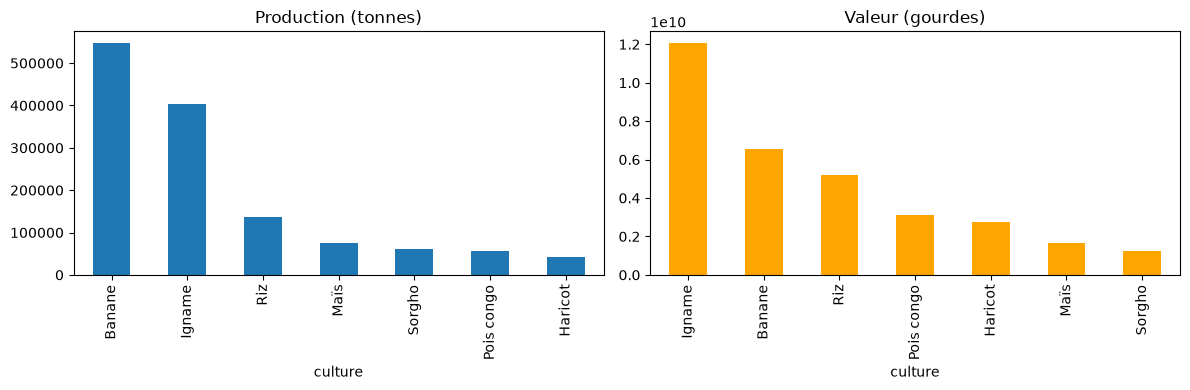

In [16]:
q1 = complet.groupby("culture").agg(tonnes=("production_t", "sum"), valeur=("valeur_htg", "sum"))
q1["rang_tonnes"] = q1.tonnes.rank(ascending=False).astype(int)
q1["rang_valeur"] = q1.valeur.rank(ascending=False).astype(int)
display(q1.sort_values("tonnes", ascending=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
q1.tonnes.sort_values(ascending=False).plot.bar(ax=ax[0], title="Production (tonnes)")
q1.valeur.sort_values(ascending=False).plot.bar(ax=ax[1], color="orange", title="Valeur (gourdes)")
plt.tight_layout()

**Ce qu'on en conclut :**

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

departement,Artibonite,Centre,Grand'Anse,Nippes,Nord,Nord-Est,Nord-Ouest,Ouest,Sud,Sud-Est
culture,,,,,,,,,,
Banane,7.10,6.64,8.66,7.21,9.05,6.23,6.55,6.89,8.01,7.04
Haricot,0.64,0.78,0.69,0.71,0.70,0.61,0.60,0.63,0.88,0.66
Igname,5.79,5.53,8.24,5.30,5.74,5.32,5.44,5.74,6.56,5.76
Maïs,0.96,1.20,1.11,1.05,1.08,0.91,0.99,1.06,1.15,0.92
Pois congo,0.77,0.82,0.73,0.76,0.74,0.63,1.01,0.80,0.80,0.76
Riz,3.80,NaN,NaN,NaN,2.43,2.12,NaN,2.38,2.68,NaN
Sorgho,0.79,1.08,0.91,0.85,0.90,0.77,0.82,0.83,0.80,0.88


culture
Banane              Nord
Haricot              Sud
Igname        Grand'Anse
Maïs              Centre
Pois congo    Nord-Ouest
Riz           Artibonite
Sorgho            Centre
dtype: str


Text(0.5, 1.0, 'Rendement (t/ha)')

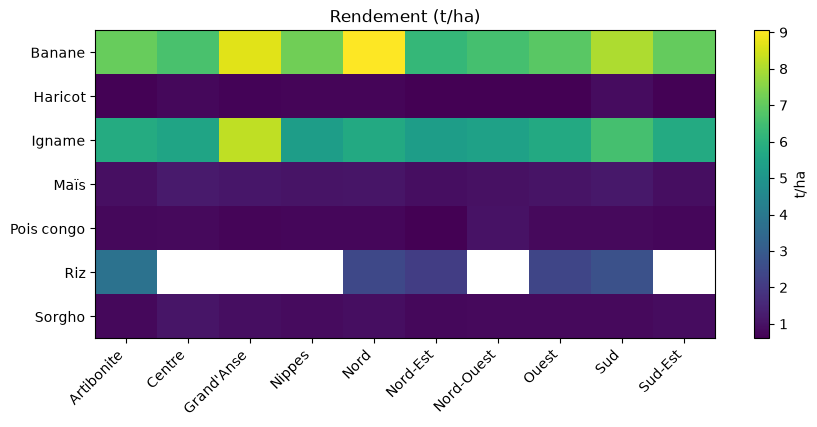

In [17]:
g = complet.groupby(["culture", "departement"]).agg(p=("production_t", "sum"), s=("surface_ha", "sum"))
g["rendement"] = g.p / g.s
tab = g.rendement.unstack().round(2)
display(tab)
print(tab.idxmax(axis=1))
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(tab.values, aspect="auto")
ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=45, ha="right")
ax.set_yticks(range(tab.shape[0]), tab.index)
plt.colorbar(im, label="t/ha"); ax.set_title("Rendement (t/ha)")

**Ce qu'on en conclut :**

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

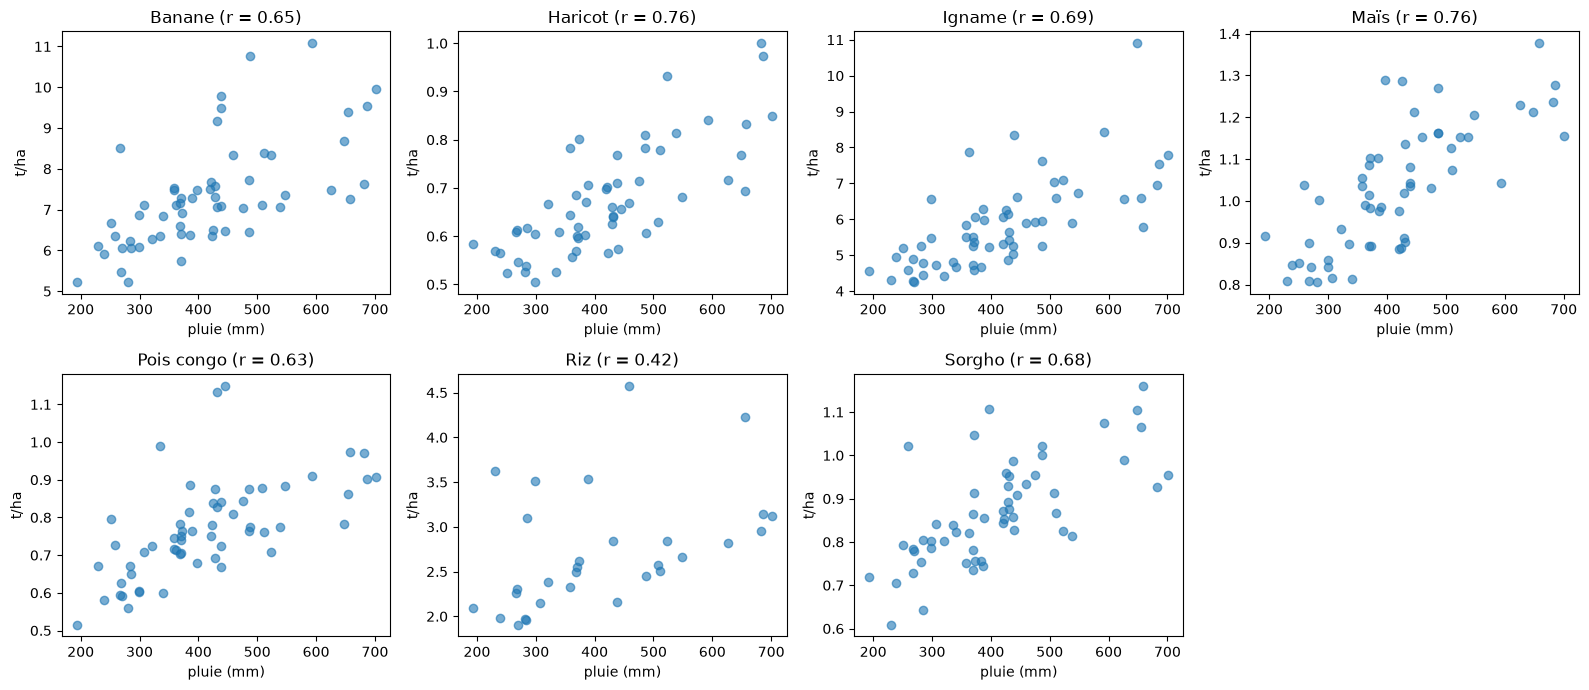

In [18]:
cult = sorted(complet.culture.unique())
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, cult):
    d = complet[complet.culture == c]
    ax.scatter(d.pluie_mm, d.rendement_t_ha, alpha=.6)
    ax.set_title(f"{c} (r = {d.pluie_mm.corr(d.rendement_t_ha):.2f})")
    ax.set_xlabel("pluie (mm)"); ax.set_ylabel("t/ha")
axes.flat[-1].axis("off")
plt.tight_layout()

**Ce qu'on en conclut :**

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

annee,2023,2024,2025,evolution_%
culture,,,,
Igname,161924.0,130569.0,109809.0,-32.2
Haricot,16081.0,12159.0,14083.0,-12.4
Maïs,27006.0,24333.0,23972.0,-11.2
Pois congo,17484.0,22271.0,16871.0,-3.5
Banane,182892.0,166401.0,198322.0,8.4
Sorgho,20478.0,16785.0,24091.0,17.6
Riz,44064.0,39660.0,52501.0,19.1


<Axes: title={'center': 'Production par année (tonnes)'}, xlabel='culture'>

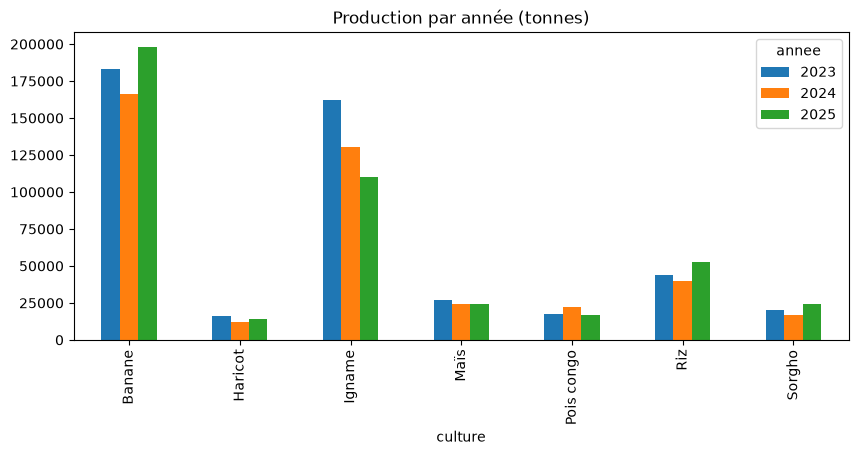

In [19]:
q4 = complet.pivot_table(index="culture", columns="annee", values="production_t", aggfunc="sum")
q4["evolution_%"] = ((q4[2025] / q4[2023] - 1) * 100).round(1)
display(q4.sort_values("evolution_%"))
q4[[2023, 2024, 2025]].plot.bar(figsize=(10, 4), title="Production par année (tonnes)")

**Ce qu'on en conclut :**

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

,t,pop,kg_par_hab_an
departement,,,
Grand'Anse,114384.0,468301,81.4
Centre,167080.0,746236,74.6
Sud,155168.0,774976,66.7
Nord-Est,75030.0,393967,63.5
Artibonite,269226.0,1727524,51.9
Nippes,49223.0,342525,47.9
Sud-Est,80796.0,632601,42.6
Nord-Ouest,87192.0,728807,39.9
Nord,118791.0,1067177,37.1


<Axes: title={'center': 'kg produits par habitant et par an'}, xlabel='departement'>

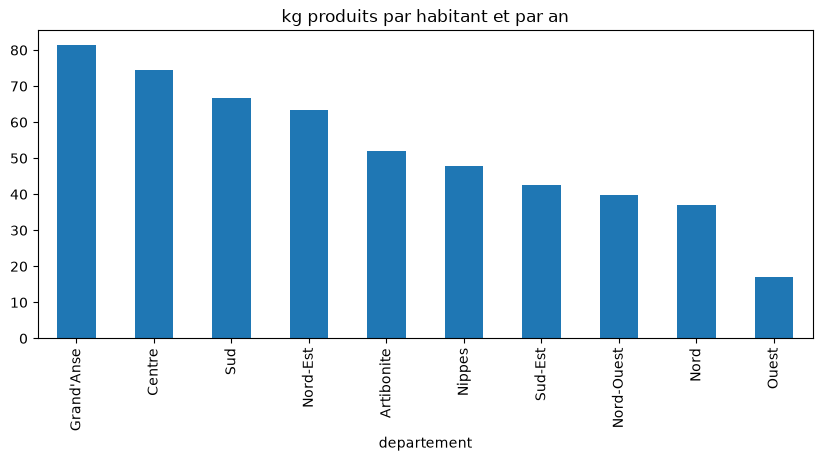

In [20]:
q5 = complet.groupby("departement").agg(t=("production_t", "sum"), pop=("population", "first"))
q5["kg_par_hab_an"] = (q5.t * 1000 / q5["pop"] / 3).round(1)
display(q5.sort_values("kg_par_hab_an", ascending=False))
q5.kg_par_hab_an.sort_values(ascending=False).plot.bar(figsize=(10, 4), title="kg produits par habitant et par an")

**Ce qu'on en conclut :**

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.